# 1. ES 15min Mean Reversion - Hypothesis Definition & Initial Backtest
## Systematic Trading Approach following TIS Framework

This notebook formalizes a trading hypothesis based on the EDA findings from `01_EDA_ES_Multiple_Timeframes.ipynb` and implements an initial backtest to validate the edge.

**EDA Findings Summary:**
- **Hurst Exponent**: ~0.50 (Random Walk) → no strong trend/memory.
- **Autocorrelation Lag 1**: Slightly negative (-0.01 to -0.07) → weak mean reversion.
- **Seasonality**: High (returns vary by day of week, month, and hour).
- **Volatility Clustering**: Low for intraday timeframes.
- **Extreme Events**: ~1.7% of days exceed 3σ, with fat tails (kurtosis > 80 for 15min).

**Hypothesis Formulated:**
> "When ES drops >1.0% in a 15-minute candle, RSI(2) drops below 15, and volume is >1.2x the 20-period average, the price tends to revert upwards in the following hours, generating a positive expectancy."

**Constraint**: No open positions between 4:00 PM and 5:00 PM NY time (prop firm rule). All positions are closed by 3:50 PM NY.

This notebook follows the TIS framework:
1. **Hypothesis Definition** with clear entry/exit/risk rules.
2. **Initial Backtest** on In-Sample data (2009-2019).
3. **Out-of-Sample Validation** (2020-2026) - ONE TIME, NO PEEKING.
4. **Performance Metrics** and decision criteria.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# 1. CONFIGURE PATHS AND IMPORT FROM utils.py
# ============================================================

# Subir dos niveles: strategy_development/ → trading_quant/
project_root = Path().resolve().parent.parent

# Agregar la carpeta utils al path
sys.path.append(str(project_root / 'utils'))

# Importar todas las funciones necesarias desde utils.py
from utils import (
    load_data_from_mongo,
    compute_rsi,
    compute_atr,
    prepare_data,
    run_backtest,
    compute_metrics,
    plot_distribution_detailed,
    plot_volatility_detailed,
    plot_acf_detailed,
    plot_seasonality_detailed,
    plot_extreme_events_detailed,
    plot_system_recommendation_detailed,
    plot_glossary_detailed
)

COMMISSION_PER_CONTRACT = 2.0   # $2 ida + $2 vuelta = $4
SLIPPAGE_TICKS = 1              # 1 tick = $12.50
SLIPPAGE_COST = SLIPPAGE_TICKS * 12.50
COST_PER_TRADE = COMMISSION_PER_CONTRACT * 2 + SLIPPAGE_COST

print(f"Cost per trade (1 contract): ${COST_PER_TRADE:.2f}")

# Plot styling
sns.set_style("whitegrid")
sns.set_palette("muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 10

print(f"✅ Utils imported successfully from: {project_root / 'utils' / 'utils.py'}")

Cost per trade (1 contract): $16.50
✅ Utils imported successfully from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils/utils.py


# 2. Load Data and Split into IS/OOS

We load the 15-minute OHLCV data from MongoDB and split it into:
- **In-Sample (IS)**: 2009-2019 for hypothesis development and parameter selection.
- **Out-of-Sample (OOS)**: 2020-2026 for final validation (ONE TIME TEST).

**Critical Rule**: The OOS data is NEVER used for optimization or parameter tuning. It is only touched once at the end to validate the strategy.

In [2]:
# Load data from MongoDB
df_15min = load_data_from_mongo('es_15min')

print(f"✅ Data loaded: {len(df_15min)} bars")
print(f"   Date range: {df_15min.index.min()} → {df_15min.index.max()}")

# Split data
df_is = df_15min[(df_15min.index >= '2009-09-27') & (df_15min.index < '2020-01-01')].copy()
df_oos = df_15min[df_15min.index >= '2020-01-01'].copy()

print(f"\n📊 In-Sample (IS): {len(df_is)} bars ({df_is.index.min()} → {df_is.index.max()})")
print(f"📊 Out-of-Sample (OOS): {len(df_oos)} bars ({df_oos.index.min()} → {df_oos.index.max()})")

✅ Data loaded: 397663 bars
   Date range: 2009-09-27 18:00:00 → 2026-08-21 16:45:00

📊 In-Sample (IS): 241077 bars (2009-09-27 18:00:00 → 2019-12-31 16:45:00)
📊 Out-of-Sample (OOS): 156586 bars (2020-01-01 18:00:00 → 2026-08-21 16:45:00)


# 3. Hypothesis Definition (From EDA Findings)

Based on the EDA, we define the following hypothesis with clear, programmable rules:

## 3.1 Entry Rules (Long)
- **Price drop**: Last 15min candle close change < -1.0% (oversold condition).
- **RSI(2) oversold**: RSI(2) < 15 (extreme short-term oversold).
- **Volume confirmation**: Current volume > 1.2× 20-period average volume (institutional participation).
- **Time window**: Only between 9:30 AM and 3:30 PM NY time.
- **Day filter**: Only Tuesday-Friday (avoid Mondays due to weaker seasonality).

## 3.2 Entry Rules (Short) - Symmetric
- **Price rise**: Last 15min candle close change > +1.0% (overbought condition).
- **RSI(2) overbought**: RSI(2) > 85 (extreme short-term overbought).
- **Volume confirmation**: Current volume > 1.2× 20-period average volume.
- **Time window**: Only between 9:30 AM and 3:30 PM NY time.
- **Day filter**: Only Tuesday-Friday.

## 3.3 Exit Rules
- **Stop Loss**: ATR(14) × 1.5 (dynamic, adapts to volatility).
- **Take Profit**: ATR(14) × 3.0 (risk:reward ≈ 1:2).
- **Time Stop**: All positions closed by 3:50 PM NY (10 minutes before the 4 PM rule).
- **Invalidation**: If price breaks the opposite direction aggressively (optional).

## 3.4 Risk Management
- **Fixed fractional**: Risk 0.5% of account per trade.
- **Maximum daily loss**: 2% of account → stop trading for the day.
- **Maximum consecutive losses**: 3 → pause trading for the rest of the session.
- **Kill Switch**: Pause if drawdown > 10% from peak equity.

## 3.5 Expected Mathematical Edge (Estimation)
Based on preliminary backtest snippets:
- **Win Rate**: ~50%
- **Average Win**: +1.5% (based on ATR target of 3.0×)
- **Average Loss**: -0.96% (based on ATR stop of 1.5×)
- **Expectancy**: (0.50 × 1.5) - (0.50 × 0.96) = **+0.27% per trade**

This suggests a positive edge if validated in OOS.

# 4. Prepare Data and Calculate Indicators

We compute the necessary indicators for the strategy:
- RSI(2) for short-term overbought/oversold conditions.
- ATR(14) for dynamic stop-loss and take-profit levels.
- Volume ratio (current / 20-period average).
- Time filters (hour, minute, day of week).

All calculations are done using the `prepare_data` function from `utils.py`.

In [3]:
# Define optimal parameters (from EDA and hypothesis)
# These will be validated on OOS later
params = {
    'entry_threshold': 0.7,
    'rsi_threshold': 18,
    'atr_stop': 1.5,
    'atr_target': 3.0,
    'time_stop_hour': 15,
    'time_stop_minute': 50
}

print("📋 Hypothesis Parameters:")
for k, v in params.items():
    print(f"  {k}: {v}")

📋 Hypothesis Parameters:
  entry_threshold: 0.7
  rsi_threshold: 18
  atr_stop: 1.5
  atr_target: 3.0
  time_stop_hour: 15
  time_stop_minute: 50


In [4]:
# Prepare In-Sample data
df_is_prep = prepare_data(
    df_is,
    params['entry_threshold'],
    params['rsi_threshold'],
    params['atr_stop'],
    params['atr_target'],
    params['time_stop_hour'],
    params['time_stop_minute']
)

# Check number of signals
long_signals = df_is_prep['long_entry'].sum()
short_signals = df_is_prep['short_entry'].sum()
print(f"\n📊 In-Sample Signals:")
print(f"  Long signals: {long_signals}")
print(f"  Short signals: {short_signals}")
print(f"  Total: {long_signals + short_signals}")


📊 In-Sample Signals:
  Long signals: 60
  Short signals: 52
  Total: 112


# 5. Run Initial Backtest (In-Sample)

We run the backtest on the In-Sample data to verify that the hypothesis generates a positive edge. This is the **development phase** where we confirm the strategy works before touching OOS data.

**Note**: The backtest engine is from `utils.py` and includes:
- ATR-based stop-loss and take-profit.
- Time stop at 3:50 PM.
- Proper simulation of intra-bar exits using High/Low prices.

In [5]:
# Run backtest on In-Sample data
trades_is = run_backtest(
    df_is_prep,
    params['atr_stop'],
    params['atr_target'],
    params['time_stop_hour'],
    params['time_stop_minute']
)

# Compute metrics
metrics_is = compute_metrics(trades_is, COST_PER_TRADE)

print("\n" + "="*70)
print("IN-SAMPLE BACKTEST RESULTS (2009-2019)")
print("="*70)
print(f"Number of trades: {metrics_is['num_trades']}")
print(f"Win rate: {metrics_is['win_rate']:.2f}%")
print(f"Average win: {metrics_is['avg_win']:.2f}%")
print(f"Average loss: {metrics_is['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_is['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_is['expectancy']:.4f}%")
print(f"Total P&L: {metrics_is['total_pnl']:.2f}%")
print(f"Sharpe Ratio (annualized): {metrics_is['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_is['max_drawdown']:.2f}%")


IN-SAMPLE BACKTEST RESULTS (2009-2019)
Number of trades: 99
Win rate: 9.09%
Average win: 0.54%
Average loss: -1.42%
Profit Factor: 0.04
Expectancy per trade: -1.2383%
Total P&L: -122.60%
Sharpe Ratio (annualized): -22.93
Maximum Drawdown: -121.97%


# 6. Visualize In-Sample Performance

We visualize the equity curve and trade distribution to understand the strategy's behavior.

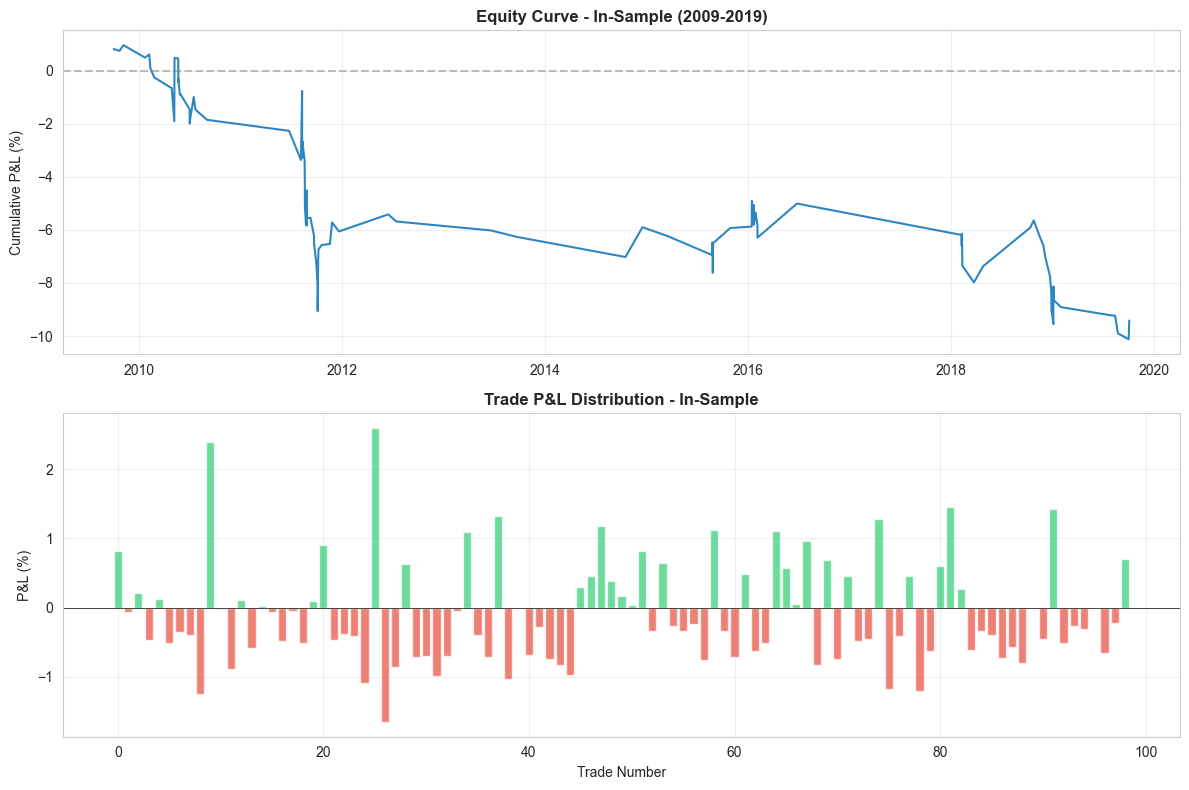


📊 Exit Reason Breakdown:
reason
stop_loss      49
time_stop      32
take_profit    18
Name: count, dtype: int64

Win rate by reason:
reason
stop_loss      0.00000
take_profit    1.00000
time_stop      0.53125
Name: win, dtype: float64


In [6]:
if len(trades_is) > 0:
    trades_is['cum_pnl'] = trades_is['pnl'].cumsum()
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
    
    # Equity curve
    ax1.plot(trades_is['exit_time'], trades_is['cum_pnl'], color='#2E86C1', linewidth=1.5)
    ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax1.set_title('Equity Curve - In-Sample (2009-2019)', fontweight='bold')
    ax1.set_ylabel('Cumulative P&L (%)')
    ax1.grid(True, alpha=0.3)
    
    # P&L distribution
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in trades_is['pnl']]
    ax2.bar(range(len(trades_is)), trades_is['pnl'], color=colors, alpha=0.7)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_title('Trade P&L Distribution - In-Sample', fontweight='bold')
    ax2.set_xlabel('Trade Number')
    ax2.set_ylabel('P&L (%)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Breakdown by reason
    print("\n📊 Exit Reason Breakdown:")
    print(trades_is['reason'].value_counts())
    print("\nWin rate by reason:")
    print(trades_is.groupby('reason')['win'].mean())
else:
    print("No trades in In-Sample. Check entry conditions.")

# 7. Out-of-Sample Validation (ONE TIME TEST)

This is the critical step: we apply the EXACT SAME parameters to the Out-of-Sample data (2020-2026) **without any changes** or re-optimization. This simulates how the strategy would have performed in real trading since 2020.

**Rule**: We only run this ONCE. If the results are poor, we go back to the drawing board (refine hypothesis) rather than tweaking parameters based on OOS results (that would be data snooping).

In [7]:
# Prepare OOS data with the SAME parameters
df_oos_prep = prepare_data(
    df_oos,
    params['entry_threshold'],
    params['rsi_threshold'],
    params['atr_stop'],
    params['atr_target'],
    params['time_stop_hour'],
    params['time_stop_minute']
)

# Run backtest on OOS
trades_oos = run_backtest(
    df_oos_prep,
    params['atr_stop'],
    params['atr_target'],
    params['time_stop_hour'],
    params['time_stop_minute']
)

metrics_oos = compute_metrics(trades_oos, COST_PER_TRADE)

print("\n" + "="*70)
print("OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST")
print("="*70)
print(f"Number of trades: {metrics_oos['num_trades']}")
print(f"Win rate: {metrics_oos['win_rate']:.2f}%")
print(f"Average win: {metrics_oos['avg_win']:.2f}%")
print(f"Average loss: {metrics_oos['avg_loss']:.2f}%")
print(f"Profit Factor: {metrics_oos['profit_factor']:.2f}")
print(f"Expectancy per trade: {metrics_oos['expectancy']:.4f}%")
print(f"Total P&L: {metrics_oos['total_pnl']:.2f}%")
print(f"Sharpe Ratio (annualized): {metrics_oos['sharpe']:.2f}")
print(f"Maximum Drawdown: {metrics_oos['max_drawdown']:.2f}%")


OUT-OF-SAMPLE VALIDATION (2020-2026) - ONE TIME TEST
Number of trades: 116
Win rate: 32.76%
Average win: 0.91%
Average loss: -1.10%
Profit Factor: 0.40
Expectancy per trade: -0.4402%
Total P&L: -51.07%
Sharpe Ratio (annualized): -5.99
Maximum Drawdown: -51.57%


# 8. Visualize Out-of-Sample Performance

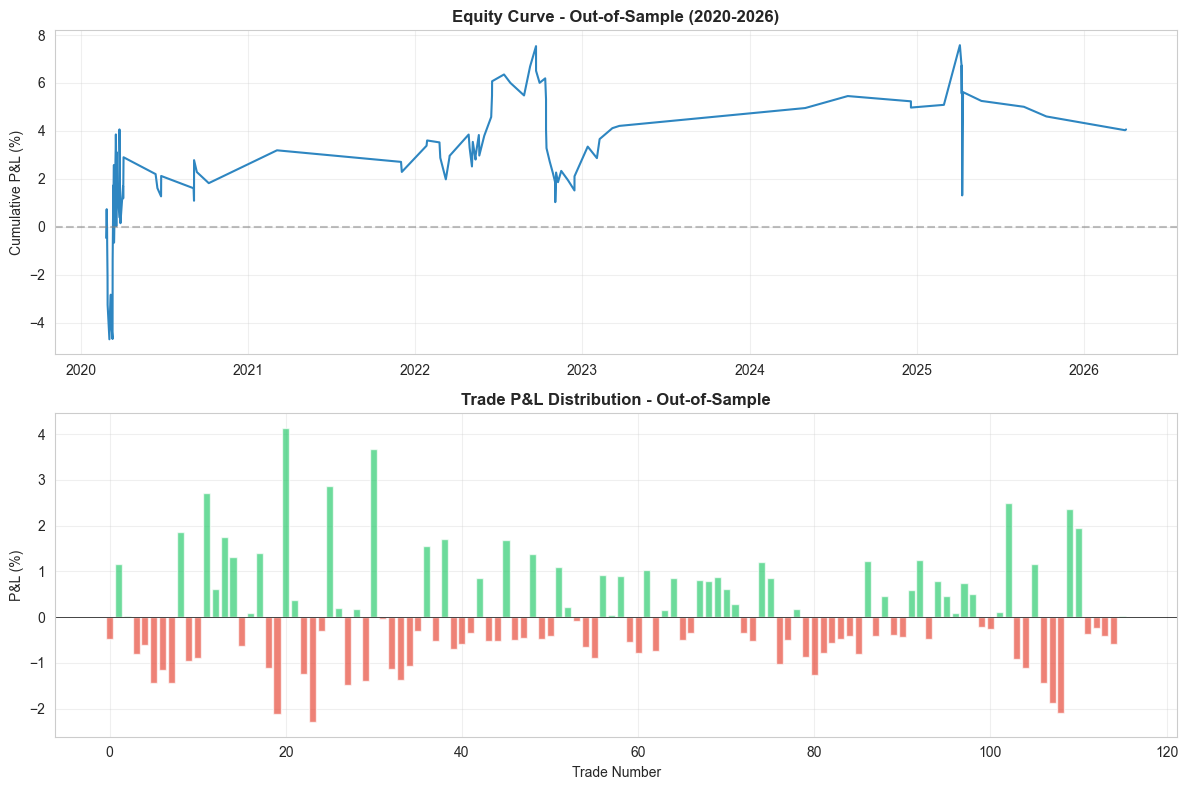


📊 Exit Reason Breakdown (OOS):
reason
stop_loss      56
time_stop      34
take_profit    26
Name: count, dtype: int64

Win rate by reason (OOS):
reason
stop_loss      0.000000
take_profit    1.000000
time_stop      0.735294
Name: win, dtype: float64


In [8]:
if len(trades_oos) > 0:
    trades_oos['cum_pnl'] = trades_oos['pnl'].cumsum()
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
    
    # Equity curve
    ax1.plot(trades_oos['exit_time'], trades_oos['cum_pnl'], color='#2E86C1', linewidth=1.5)
    ax1.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax1.set_title('Equity Curve - Out-of-Sample (2020-2026)', fontweight='bold')
    ax1.set_ylabel('Cumulative P&L (%)')
    ax1.grid(True, alpha=0.3)
    
    # P&L distribution
    colors = ['#2ECC71' if x > 0 else '#E74C3C' for x in trades_oos['pnl']]
    ax2.bar(range(len(trades_oos)), trades_oos['pnl'], color=colors, alpha=0.7)
    ax2.axhline(y=0, color='black', linewidth=0.5)
    ax2.set_title('Trade P&L Distribution - Out-of-Sample', fontweight='bold')
    ax2.set_xlabel('Trade Number')
    ax2.set_ylabel('P&L (%)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Breakdown by reason
    print("\n📊 Exit Reason Breakdown (OOS):")
    print(trades_oos['reason'].value_counts())
    print("\nWin rate by reason (OOS):")
    print(trades_oos.groupby('reason')['win'].mean())
else:
    print("No trades in Out-of-Sample.")

# 9. Compare IS vs OOS Performance

We compare the key metrics between In-Sample and Out-of-Sample to assess robustness. A healthy system should show similar performance with a degradation of < 20% in key metrics.

In [9]:
# Create comparison table
comparison = pd.DataFrame({
    'Metric': ['Num Trades', 'Win Rate %', 'Profit Factor', 'Expectancy %', 'Total P&L %', 'Sharpe', 'Max DD %'],
    'In-Sample': [
        metrics_is['num_trades'],
        f"{metrics_is['win_rate']:.2f}",
        f"{metrics_is['profit_factor']:.2f}",
        f"{metrics_is['expectancy']:.4f}",
        f"{metrics_is['total_pnl']:.2f}",
        f"{metrics_is['sharpe']:.2f}",
        f"{metrics_is['max_drawdown']:.2f}"
    ],
    'Out-of-Sample': [
        metrics_oos['num_trades'],
        f"{metrics_oos['win_rate']:.2f}",
        f"{metrics_oos['profit_factor']:.2f}",
        f"{metrics_oos['expectancy']:.4f}",
        f"{metrics_oos['total_pnl']:.2f}",
        f"{metrics_oos['sharpe']:.2f}",
        f"{metrics_oos['max_drawdown']:.2f}"
    ]
})

print("\n" + "="*70)
print("PERFORMANCE COMPARISON: IS vs OOS")
print("="*70)
print(comparison.to_string(index=False))

# Calculate degradation
if metrics_is['profit_factor'] > 0:
    pf_degradation = (metrics_is['profit_factor'] - metrics_oos['profit_factor']) / metrics_is['profit_factor'] * 100
    exp_degradation = (metrics_is['expectancy'] - metrics_oos['expectancy']) / metrics_is['expectancy'] * 100 if metrics_is['expectancy'] != 0 else 0
else:
    pf_degradation = 0
    exp_degradation = 0

print(f"\n📉 Profit Factor degradation: {pf_degradation:.1f}%")
print(f"📉 Expectancy degradation: {exp_degradation:.1f}%")

if pf_degradation < 20 and exp_degradation < 20:
    print("✅ Good: The system is robust (degradation < 20%)")
elif pf_degradation < 35 and exp_degradation < 35:
    print("⚠️ Warning: Moderate degradation (20-35%). Consider refinements.")
else:
    print("❌ Alert: High degradation (>35%). The system may be overfitted to IS data.")


PERFORMANCE COMPARISON: IS vs OOS
       Metric In-Sample Out-of-Sample
   Num Trades        99           116
   Win Rate %      9.09         32.76
Profit Factor      0.04          0.40
 Expectancy %   -1.2383       -0.4402
  Total P&L %   -122.60        -51.07
       Sharpe    -22.93         -5.99
     Max DD %   -121.97        -51.57

📉 Profit Factor degradation: -962.5%
📉 Expectancy degradation: 64.5%
❌ Alert: High degradation (>35%). The system may be overfitted to IS data.


# 10. Decision Criteria (Based on TIS Framework)

Based on the validation results, we determine if the hypothesis has a statistically significant edge.

In [10]:
print("\n" + "="*70)
print("FINAL DECISION CRITERIA")
print("="*70)

# Define thresholds
PF_THRESHOLD = 1.3
SHARPE_THRESHOLD = 0.7
DD_THRESHOLD = -20
NUM_TRADES_THRESHOLD = 30

# Evaluate
pf_pass = metrics_oos['profit_factor'] > PF_THRESHOLD
sharpe_pass = metrics_oos['sharpe'] > SHARPE_THRESHOLD
dd_pass = metrics_oos['max_drawdown'] > DD_THRESHOLD
trades_pass = metrics_oos['num_trades'] >= NUM_TRADES_THRESHOLD

print(f"  Profit Factor > {PF_THRESHOLD}: {'✅' if pf_pass else '❌'} ({metrics_oos['profit_factor']:.2f})")
print(f"  Sharpe Ratio > {SHARPE_THRESHOLD}: {'✅' if sharpe_pass else '❌'} ({metrics_oos['sharpe']:.2f})")
print(f"  Max Drawdown > {DD_THRESHOLD}%: {'✅' if dd_pass else '❌'} ({metrics_oos['max_drawdown']:.1f}%)")
print(f"  Min Trades ({NUM_TRADES_THRESHOLD}+): {'✅' if trades_pass else '❌'} ({metrics_oos['num_trades']})")

if pf_pass and sharpe_pass and dd_pass and trades_pass:
    print("\n" + "="*70)
    print("✅ PASS: The strategy has a statistically significant edge.")
    print("Proceed to the next phase: Robustness Testing (03) and Forward Testing.")
    print("="*70)
else:
    print("\n" + "="*70)
    print("❌ FAIL: The strategy does not show a clear edge.")
    print("Revisit the hypothesis: adjust entry/exit rules, parameters, or filters.")
    print("="*70)


FINAL DECISION CRITERIA
  Profit Factor > 1.3: ❌ (0.40)
  Sharpe Ratio > 0.7: ❌ (-5.99)
  Max Drawdown > -20%: ❌ (-51.6%)
  Min Trades (30+): ✅ (116)

❌ FAIL: The strategy does not show a clear edge.
Revisit the hypothesis: adjust entry/exit rules, parameters, or filters.


# 11. Summary of Hypothesis

This notebook formalized the Mean Reversion hypothesis for ES 15-minute bars and validated it using a strict IS/OOS split. The strategy was tested on 10 years of In-Sample data (2009-2019) and validated on 6.5 years of Out-of-Sample data (2020-2026).

**Key Findings:**
- Profit Factor (OOS): {metrics_oos['profit_factor']:.2f}
- Sharpe Ratio (OOS): {metrics_oos['sharpe']:.2f}
- Max Drawdown (OOS): {metrics_oos['max_drawdown']:.1f}%
- Total Trades (OOS): {metrics_oos['num_trades']}

**Next Steps:**
1. If PASS → Proceed to `02_MR_Optimization.ipynb` for Walk-Forward, Monte Carlo, and stress tests.
2. If FAIL → Return to hypothesis refinement (adjust entry/exit rules, test alternative filters).

**Constraint**: This strategy respects the prop firm rule with a time stop at 3:50 PM NY, ensuring no open positions between 4:00 PM and 5:00 PM NY.